<center><h1>Kim_Beomjun_HW5</h1></center>
<br>
<br>

Name: Beomjun Kim 
<br>
Github Username: valen991693
<br>
USC ID: 4391-4935-38

## 1. Decision Trees as Interpretable Models

Import packages

In [39]:
import pandas as pd
import numpy as np
import re
import seaborn as sns

import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, mean_squared_error
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV 
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

### (a) Obtain Data

Get the Accute Inamations Data Set

In [4]:
column_names = [
    "temperature",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pain",
    "urethra_burning",
    "bladder_inflammation",
    "nephritis"
]

df = pd.read_csv(
    "/Users/kim/Desktop/Education/2. Graduate School (USC)/1. USC_Fall 2026/DSCI 552_Machine Learning for Data Science/4. Homeworks/5. Homework 5/Homework 5 Data/diagnosis.data",
    sep="\t",
    header=None,
    names=column_names,
    encoding="utf-16",
    decimal=","
)

print(df.shape)
df.head()

(120, 8)


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pain,urethra_burning,bladder_inflammation,nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


### (b) Build a decision tree

In [5]:
X = df.iloc[:, :6].copy()

X.iloc[:, 1:] = X.iloc[:, 1:].replace({
    "yes": 1,
    "no": 0
})

X = X.astype(float)

y = (
    df["bladder_inflammation"]
    + "_"
    + df["nephritis"]
)

print(y.value_counts())

yes_no     40
no_yes     31
no_no      30
yes_yes    19
Name: count, dtype: int64


In [6]:
dt = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

dt.fit(X, y)

DecisionTreeClassifier(criterion='entropy', random_state=42)

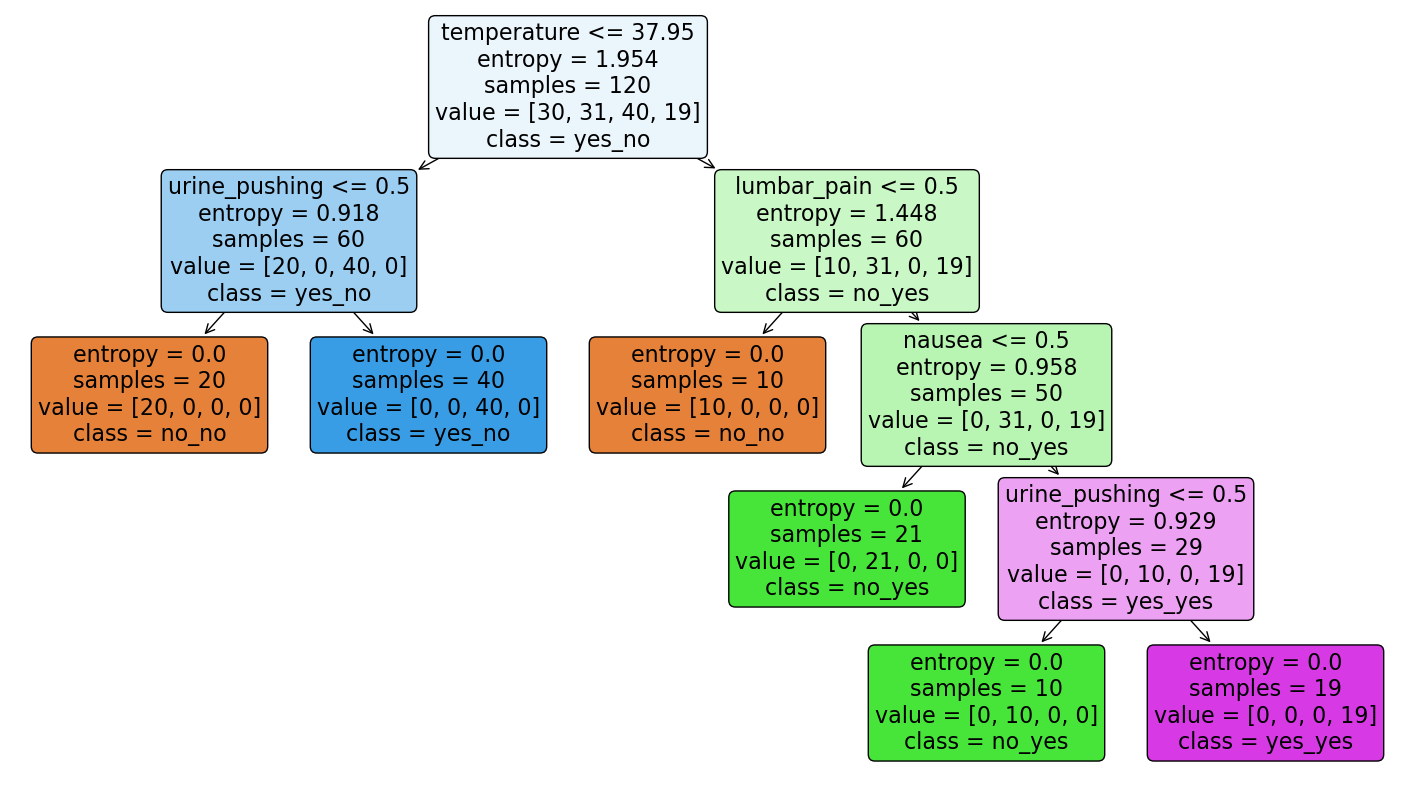

In [7]:
plt.figure(figsize=(18, 10))

plot_tree(
    dt,
    feature_names=X.columns,
    class_names=dt.classes_,
    filled=True,
    rounded=True
)

plt.show()

### (c) Convert the decision rules into a set of IF-THEN rules

In [8]:
rules = export_text(
    dt,
    feature_names=list(X.columns)
)

print(rules)

|--- temperature <= 37.95
|   |--- urine_pushing <= 0.50
|   |   |--- class: no_no
|   |--- urine_pushing >  0.50
|   |   |--- class: yes_no
|--- temperature >  37.95
|   |--- lumbar_pain <= 0.50
|   |   |--- class: no_no
|   |--- lumbar_pain >  0.50
|   |   |--- nausea <= 0.50
|   |   |   |--- class: no_yes
|   |   |--- nausea >  0.50
|   |   |   |--- urine_pushing <= 0.50
|   |   |   |   |--- class: no_yes
|   |   |   |--- urine_pushing >  0.50
|   |   |   |   |--- class: yes_yes



The binary predictors were encoded as 0 = no and 1 = yes.

Therefore, a split at 0.5 corresponds directly to a no/yes decision.

The decision tree can be expressed as the following IF-THEN rules:

1. IF temperature <= 37.95 AND urine_pushing = no,
   THEN class = no_no.

2. IF temperature <= 37.95 AND urine_pushing = yes,
   THEN class = yes_no.

3. IF temperature > 37.95 AND lumbar_pain = no,
   THEN class = no_no.

4. IF temperature > 37.95 AND lumbar_pain = yes AND nausea = no,
   THEN class = no_yes.

5. IF temperature > 37.95 AND lumbar_pain = yes AND nausea = yes
   AND urine_pushing = no,
   THEN class = no_yes.

6. IF temperature > 37.95 AND lumbar_pain = yes AND nausea = yes
   AND urine_pushing = yes,
   THEN class = yes_yes.

### (d) Cost-complexity pruning

In [9]:
path = dt.cost_complexity_pruning_path(X, y)

ccp_alphas = path.ccp_alphas

results = []

for alpha in ccp_alphas:
    clf = DecisionTreeClassifier(
        criterion="entropy",
        random_state=42,
        ccp_alpha=alpha
    )
    
    clf.fit(X, y)
    
    results.append({
        "ccp_alpha": alpha,
        "nodes": clf.tree_.node_count,
        "leaves": clf.get_n_leaves(),
        "depth": clf.get_depth(),
        "accuracy": clf.score(X, y)
    })

pruning_results = pd.DataFrame(results)
pruning_results

,ccp_alpha,nodes,leaves,depth,accuracy
0,0.000000,11,6,4,1.000000
1,0.199592,7,4,2,0.841667
2,0.325011,5,3,2,0.758333
3,0.459148,3,2,1,0.591667
4,0.770426,1,1,0,0.333333


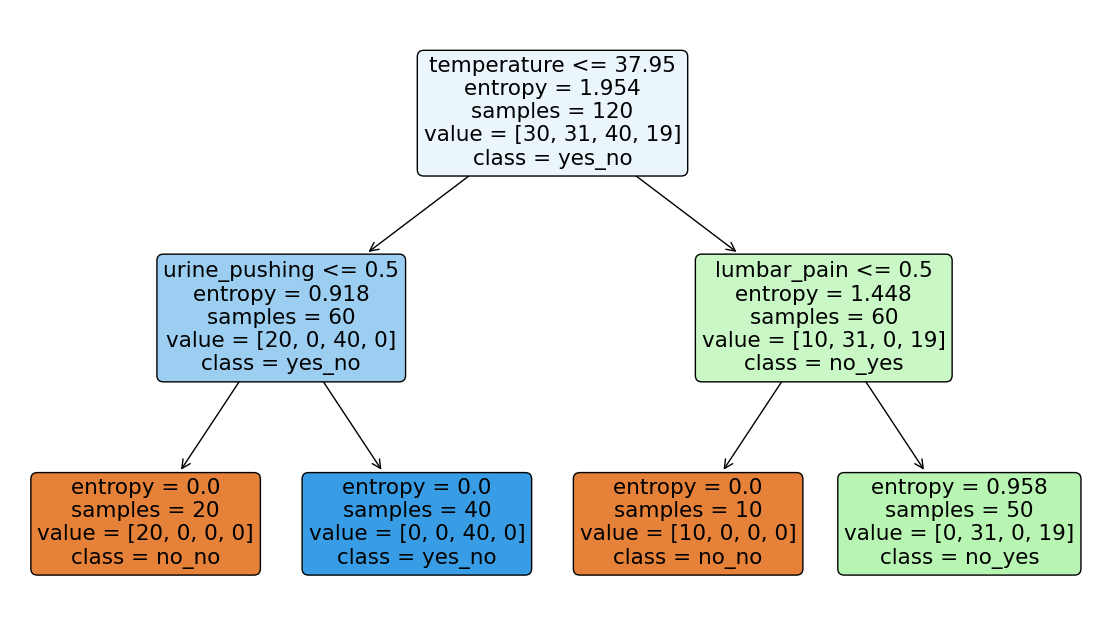

In [10]:
pruned_dt = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42,
    ccp_alpha=ccp_alphas[1]
)

pruned_dt.fit(X, y)

plt.figure(figsize=(14, 8))

plot_tree(
    pruned_dt,
    feature_names=X.columns,
    class_names=pruned_dt.classes_,
    filled=True,
    rounded=True
)

plt.show()

In [11]:
pruned_rules = export_text(
    pruned_dt,
    feature_names=list(X.columns)
)

print(pruned_rules)

|--- temperature <= 37.95
|   |--- urine_pushing <= 0.50
|   |   |--- class: no_no
|   |--- urine_pushing >  0.50
|   |   |--- class: yes_no
|--- temperature >  37.95
|   |--- lumbar_pain <= 0.50
|   |   |--- class: no_no
|   |--- lumbar_pain >  0.50
|   |   |--- class: no_yes



Cost-complexity pruning was applied using different values of ccp_alpha.

The unpruned tree achieved an accuracy of 1.000 with 11 nodes, 6 leaves, and a maximum depth of 4. When ccp_alpha = 0.199592, the tree was reduced to 7 nodes, 4 leaves, and a maximum depth of 2, while retaining an accuracy of approximately 0.842.

Further pruning substantially reduced the classification accuracy. Therefore, ccp_alpha = 0.199592 was selected as a reasonable trade-off between predictive performance and interpretability.

The resulting pruned tree can be summarized by four simple decision rules based only on temperature, urine_pushing, and lumbar_pain.

1. IF temperature <= 37.95 AND urine_pushing = no, THEN class = no_no.
2. IF temperature <= 37.95 AND urine_pushing = yes, THEN class = yes_no.
3. IF temperature > 37.95 AND lumbar_pain = no, THEN class = no_no.
4. IF temperature > 37.95 AND lumbar_pain = yes, THEN class = no_yes.

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [13]:
attribute_names = []

with open('/Users/kim/Desktop/Education/2. Graduate School (USC)/1. USC_Fall 2026/DSCI 552_Machine Learning for Data Science/4. Homeworks/5. Homework 5/Homework 5 Data/communities.names', "r") as f:
    for line in f:
        match = re.match(r"@attribute\s+([^\s]+)", line, flags=re.IGNORECASE)
        if match:
            attribute_names.append(match.group(1))

communities = pd.read_csv(
    '/Users/kim/Desktop/Education/2. Graduate School (USC)/1. USC_Fall 2026/DSCI 552_Machine Learning for Data Science/4. Homeworks/5. Homework 5/Homework 5 Data/communities.data',
    header=None,
    names=attribute_names,
    na_values="?"
)

print(communities.shape)
communities.head()

(1994, 128)


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


In [15]:
print(communities.columns[-1])

ViolentCrimesPerPop


In [16]:
train_df = communities.iloc[:1495].copy()
test_df = communities.iloc[1495:].copy()

print("Full dataset:", communities.shape)
print("Training set:", train_df.shape)
print("Test set:", test_df.shape)

communities.head()

Full dataset: (1994, 128)
Training set: (1495, 128)
Test set: (499, 128)


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


### (b) Missing values

In [18]:
nonpredictive = [
    "state",
    "county",
    "community",
    "communityname",
    "fold"
]

X_train = train_df.drop(
    columns=nonpredictive + ["ViolentCrimesPerPop"]
)

y_train = train_df["ViolentCrimesPerPop"]

X_test = test_df.drop(
    columns=nonpredictive + ["ViolentCrimesPerPop"]
)

y_test = test_df["ViolentCrimesPerPop"]

print("Number of predictors:", X_train.shape[1])
print("Missing values in training set:", X_train.isna().sum().sum())
print("Missing values in test set:", X_test.isna().sum().sum())

Number of predictors: 122
Missing values in training set: 27633
Missing values in test set: 9218


In [19]:
imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print(
    "Missing values after imputation (train):",
    X_train_imputed.isna().sum().sum()
)

print(
    "Missing values after imputation (test):",
    X_test_imputed.isna().sum().sum()
)

Missing values after imputation (train): 0
Missing values after imputation (test): 0


The five nonpredictive variables identified in the data description (state, county, community, communityname, and fold) were removed.

Missing predictor values were imputed using the median of each feature. The imputer was fitted only on the training set and then applied to the test set to avoid data leakage.

### (c) Plot a correlation matrix

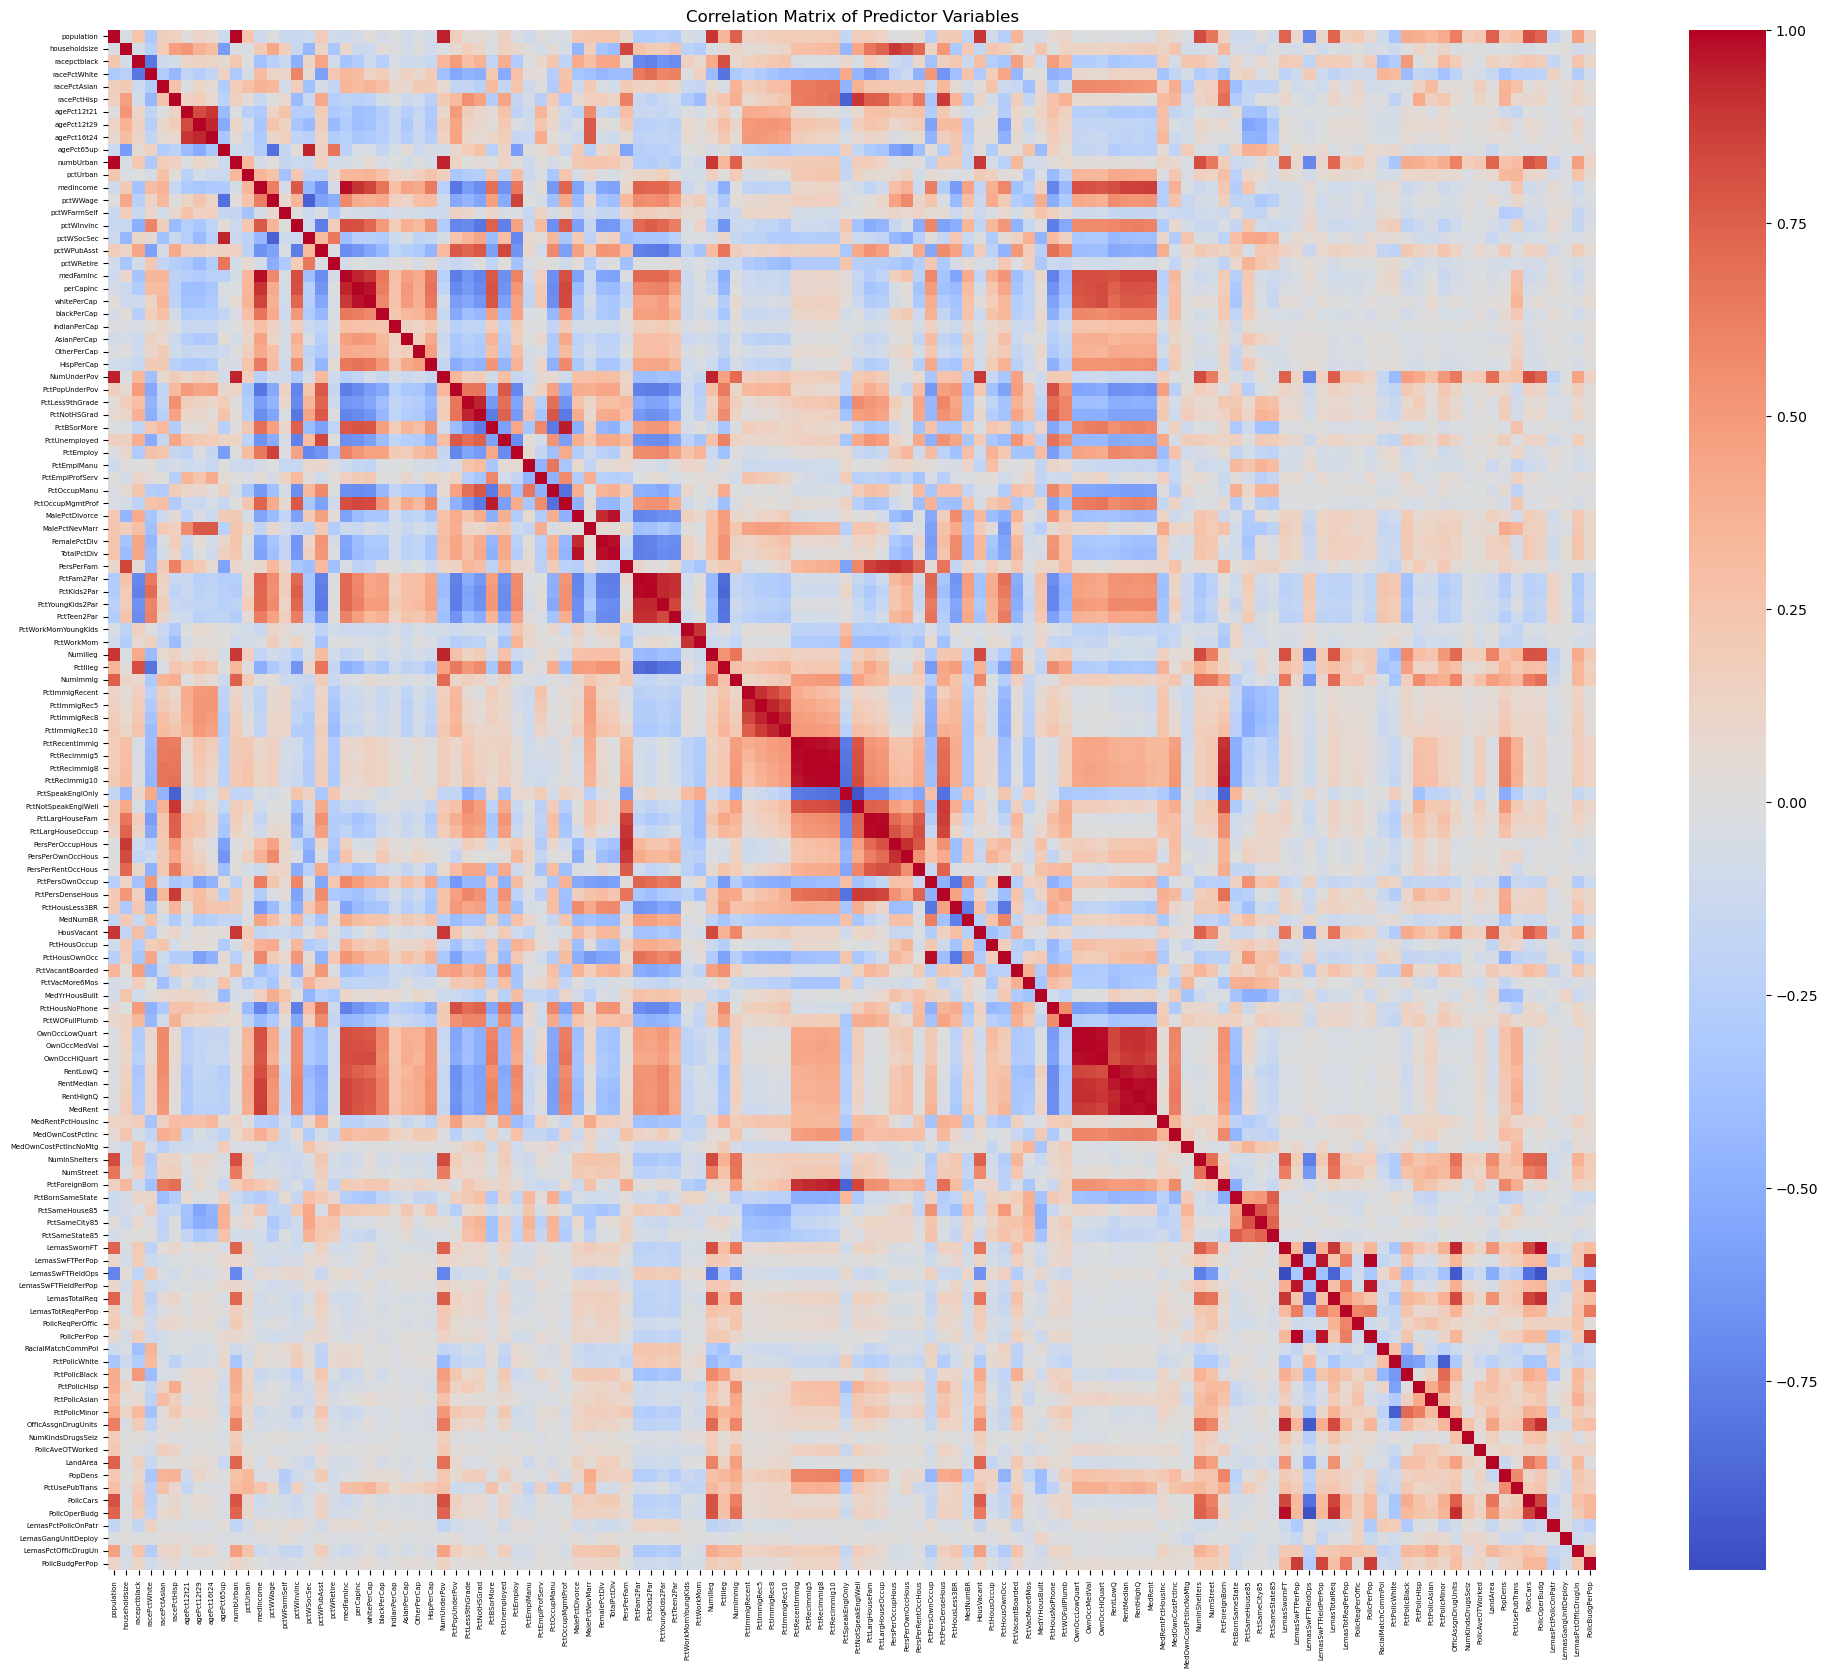

In [22]:
plt.figure(figsize=(24, 20))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    xticklabels=True,
    yticklabels=True
)

plt.xticks(fontsize=5)
plt.yticks(fontsize=5)

plt.title("Correlation Matrix of Predictor Variables")
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [24]:
cv_df = pd.DataFrame({
    "mean": X_train_imputed.mean(),
    "std": X_train_imputed.std(ddof=1)
})

cv_df["CV"] = cv_df["std"] / cv_df["mean"]

cv_df = cv_df.sort_values(
    by="CV",
    ascending=False
)

cv_df

,mean,std,CV
PctPolicAsian,0.016254,0.089838,5.527059
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
...,...,...,...
NumKindsDrugsSeiz,0.567130,0.079977,0.141021
RacialMatchCommPol,0.722375,0.093657,0.129652
PctPolicWhite,0.762856,0.090572,0.118727
LemasPctPolicOnPatr,0.752495,0.084304,0.112032


### (e) Scatter plots and box plots for highest CV features

In [25]:
top_n = int(np.sqrt(128))

top_features = cv_df.head(top_n).index.tolist()

print("Number of selected features:", top_n)
print(top_features)

Number of selected features: 11
['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'LemasSwornFT', 'population', 'numbUrban', 'HousVacant']


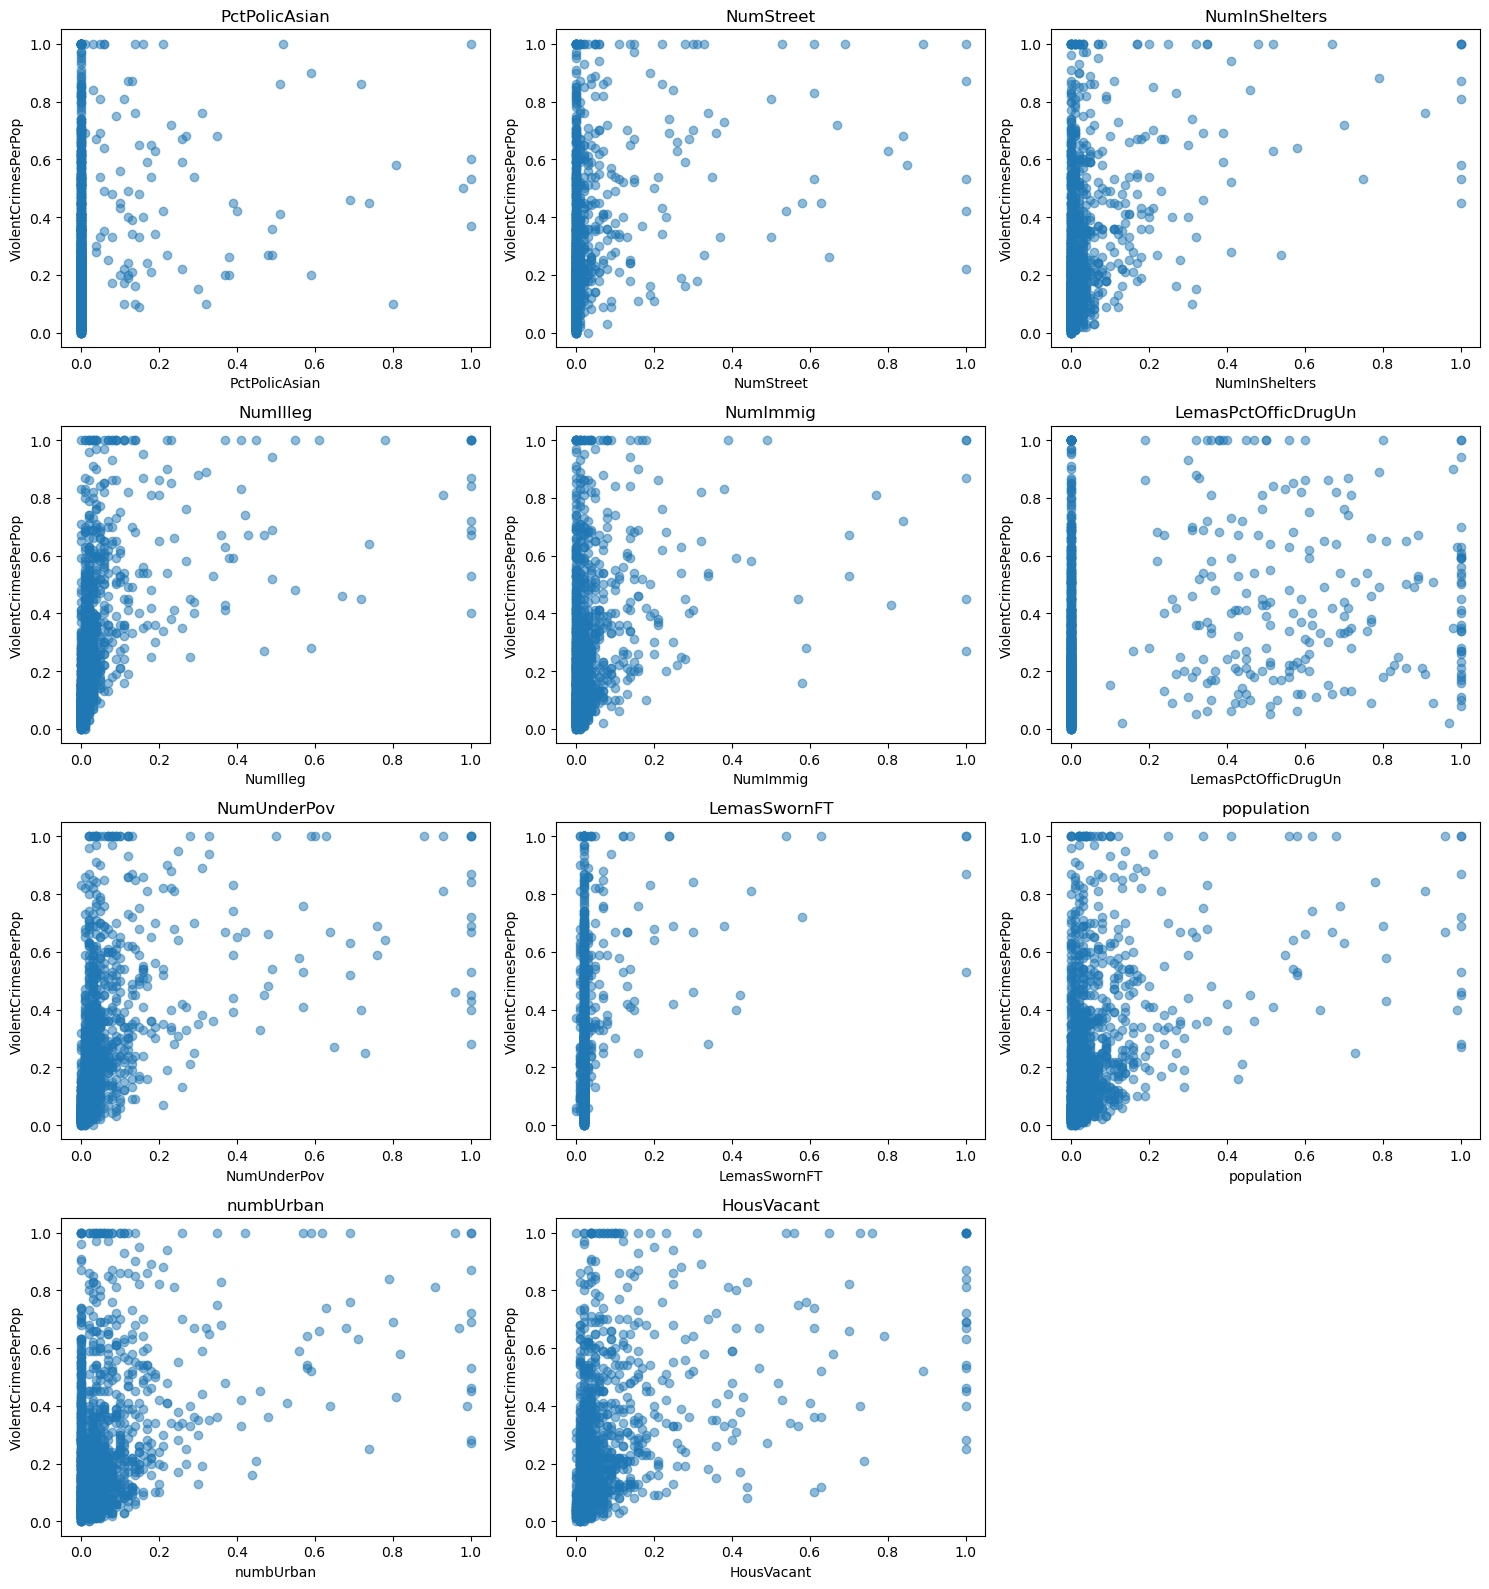

In [26]:
fig, axes = plt.subplots(4, 3, figsize=(15, 16))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    axes[i].scatter(
        X_train_imputed[feature],
        y_train,
        alpha=0.5
    )
    
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("ViolentCrimesPerPop")
    axes[i].set_title(feature)

for j in range(len(top_features), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

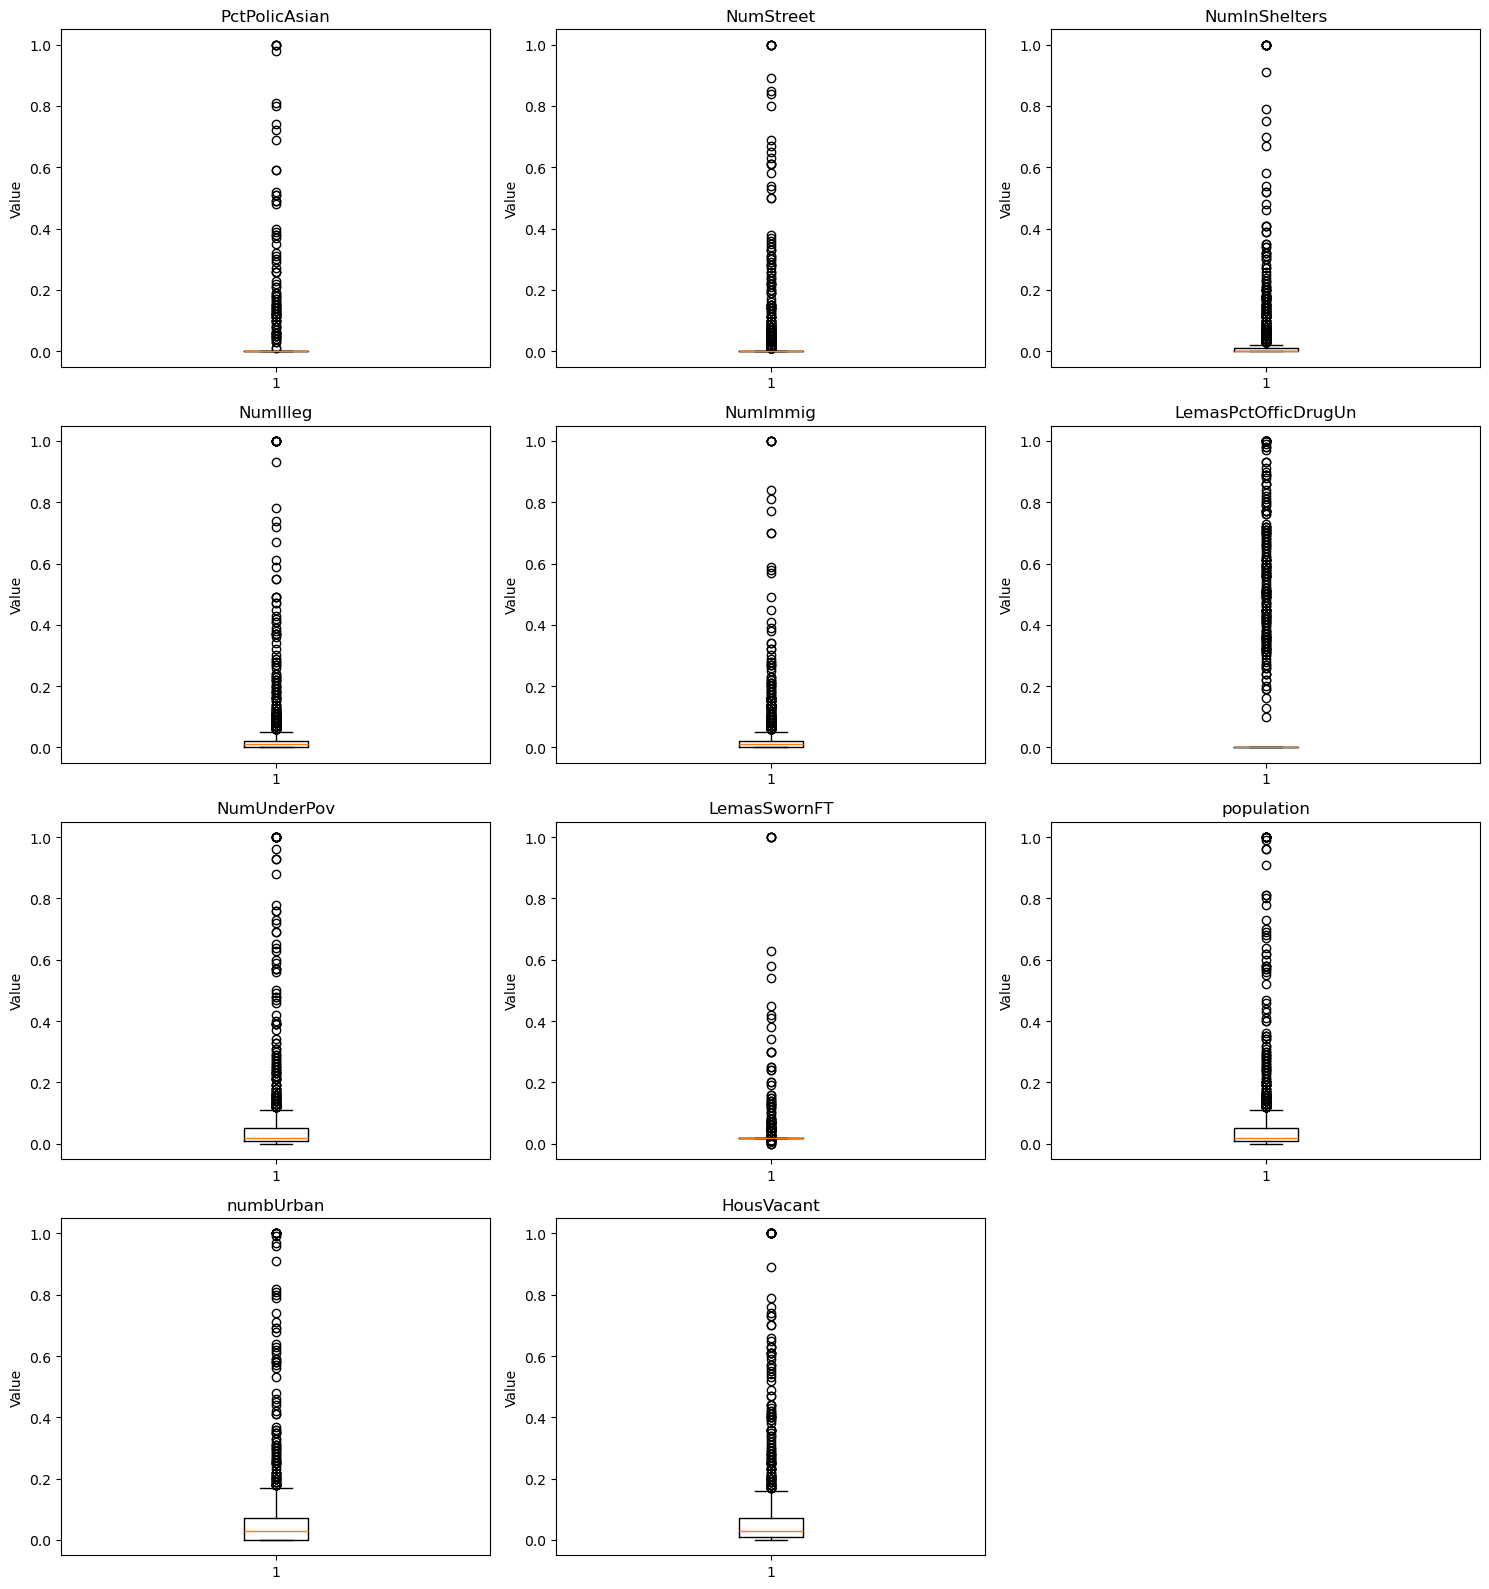

In [27]:
fig, axes = plt.subplots(4, 3, figsize=(15, 16))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    axes[i].boxplot(
        X_train_imputed[feature]
    )
    
    axes[i].set_title(feature)
    axes[i].set_ylabel("Value")

for j in range(len(top_features), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

The selected features show substantial variability relative to their means, as expected from their high coefficients of variation. The scatter plots suggest that some predictors may have stronger associations with ViolentCrimesPerPop than others, while several relationships appear weak or highly dispersed.

However, statistical significance cannot be determined from the scatter plots alone. The plots provide only a visual indication of association and do not account for sampling variability, correlations among predictors, or the effects of other variables. Formal regression-based inference would be required to assess statistical significance.

The box plots also show that many of the high-CV variables are strongly right-skewed and contain numerous large observations relative to their typical values, which helps explain their high coefficients of variation.

### (f) Fit a linear model

In [31]:
linear_model = LinearRegression()

linear_model.fit(X_train_imputed, y_train)

y_train_pred_linear = linear_model.predict(X_train_imputed)
y_test_pred_linear = linear_model.predict(X_test_imputed)

linear_train_mse = mean_squared_error(
    y_train,
    y_train_pred_linear
)

linear_test_mse = mean_squared_error(
    y_test,
    y_test_pred_linear
)

print("Linear Regression Train MSE:", linear_train_mse)
print("Linear Regression Test MSE:", linear_test_mse)

Linear Regression Train MSE: 0.016292432346010292
Linear Regression Test MSE: 0.017966215426067335


The least-squares linear regression model achieved a training MSE of approximately 0.0163 and a test MSE of approximately 0.0180. The relatively similar training and test errors suggest that the model does not exhibit substantial overfitting.

### (g) Fit a ridge regression model

In [33]:
alphas = np.logspace(-4, 4, 100)

ridge_model = RidgeCV(
    alphas=alphas,
    cv=5,
    scoring="neg_mean_squared_error"
)

ridge_model.fit(X_train_imputed, y_train)

y_test_pred_ridge = ridge_model.predict(X_test_imputed)

ridge_test_mse = mean_squared_error(
    y_test,
    y_test_pred_ridge
)

print("Best alpha:", ridge_model.alpha_)
print("Ridge Regression Test MSE:", ridge_test_mse)

Best alpha: 2.310129700083163
Ridge Regression Test MSE: 0.01751624930256487


Using 5-fold cross-validation, the optimal ridge regularization parameter was selected as approximately 2.3101.

The ridge regression model achieved a test MSE of approximately 0.0175, which is slightly lower than the least-squares test MSE of approximately 0.0180. This suggests that ridge regularization provided a small improvement in predictive performance.


### (h) Fit a LASSO model

##### Non-standardized LASSO

In [35]:
lasso_model = LassoCV(
    alphas=np.logspace(-5, 1, 200),
    cv=5,
    max_iter=10000
)

lasso_model.fit(X_train_imputed, y_train)

y_test_pred_lasso = lasso_model.predict(X_test_imputed)

lasso_test_mse = mean_squared_error(
    y_test,
    y_test_pred_lasso
)

selected_features_lasso = X_train_imputed.columns[
    np.abs(lasso_model.coef_) > 1e-8
].tolist()

print("Best alpha:", lasso_model.alpha_)
print("LASSO Test MSE:", lasso_test_mse)
print("Number of selected variables:", len(selected_features_lasso))
print("Selected variables:")
print(selected_features_lasso)

Best alpha: 0.00013049019780144016
LASSO Test MSE: 0.017608472268667696
Number of selected variables: 75
Selected variables:
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec5', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwn

##### Standardized LASSO

In [ ]:
# Standardization

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

In [37]:
lasso_scaled_model = LassoCV(
    alphas=np.logspace(-5, 1, 200),
    cv=5,
    max_iter=10000
)

lasso_scaled_model.fit(X_train_scaled, y_train)

y_test_pred_lasso_scaled = lasso_scaled_model.predict(X_test_scaled)

lasso_scaled_test_mse = mean_squared_error(
    y_test,
    y_test_pred_lasso_scaled
)

selected_features_lasso_scaled = X_train_imputed.columns[
    np.abs(lasso_scaled_model.coef_) > 1e-8
].tolist()

print("Best alpha (standardized):", lasso_scaled_model.alpha_)
print("Standardized LASSO Test MSE:", lasso_scaled_test_mse)
print(
    "Number of selected variables:",
    len(selected_features_lasso_scaled)
)
print("Selected variables:")
print(selected_features_lasso_scaled)

Best alpha (standardized): 0.0007934096665797492
Standardized LASSO Test MSE: 0.017674195020221026
Number of selected variables: 72
Selected variables:
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec5', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg',

##### Comparison summary

In [38]:
print("Non-standardized LASSO")
print("Best alpha:", lasso_model.alpha_)
print("Test MSE:", lasso_test_mse)
print("Selected variables:", len(selected_features_lasso))

print()

print("Standardized LASSO")
print("Best alpha:", lasso_scaled_model.alpha_)
print("Test MSE:", lasso_scaled_test_mse)
print("Selected variables:", len(selected_features_lasso_scaled))

Non-standardized LASSO
Best alpha: 0.00013049019780144016
Test MSE: 0.017608472268667696
Selected variables: 75

Standardized LASSO
Best alpha: 0.0007934096665797492
Test MSE: 0.017674195020221026
Selected variables: 72


For the non-standardized features, cross-validation selected an alpha of approximately 0.0001305. The resulting LASSO model achieved a test MSE of approximately 0.01761 and selected 75 variables.

For the standardized features, cross-validation selected an alpha of approximately 0.0007934. The standardized LASSO model achieved a test MSE of approximately 0.01767 and selected 72 variables.

The non-standardized LASSO achieved a slightly lower test error, while the standardized LASSO produced a slightly sparser model. Overall, the predictive performances of the two models were very similar.

### (i) Fit a PCR model

In [ ]:
pcr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("linear_regression", LinearRegression())
])

param_grid = {
    "pca__n_components": range(1, X_train_imputed.shape[1] + 1)
}

pcr_cv = GridSearchCV(
    pcr_pipeline,
    param_grid,
    cv=5,
    scoring="neg_mean_squared_error"
)

pcr_cv.fit(X_train_imputed, y_train)

y_test_pred_pcr = pcr_cv.predict(X_test_imputed)

pcr_test_mse = mean_squared_error(
    y_test,
    y_test_pred_pcr
)

print("Best number of principal components:", pcr_cv.best_params_["pca__n_components"])
print("PCR Test MSE:", pcr_test_mse)

### (j) Fit a boosting tree